# 01 · Filtrado colaborativo: la matriz, los sesgos y los vecinos

**Objetivo:** entender la forma de los datos de recomendación (una matriz casi vacía con cola larga),
por qué los **sesgos** de usuario e ítem explican gran parte de las calificaciones, y cómo el
filtrado por **vecinos** agrega lo que los sesgos no ven.

Datos sintéticos de `applied_recsys.synthetic`: gusto de bajo rango, popularidad de cola larga y
faltantes **no aleatorios** (uno califica más lo que eligió ver porque le iba a gustar).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from applied_recsys.baselines import BiasModel, popularity_scores
from applied_recsys.data import random_split, to_csr
from applied_recsys.synthetic import synthetic_ratings

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_recsys.neighbors import ItemKNN

df, truth = synthetic_ratings(n_users=1500, n_items=800, density=0.04, seed=0)
shape = (1500, 800)
print(f"{len(df):,} calificaciones, densidad {len(df) / (shape[0] * shape[1]):.1%}")

40,511 calificaciones, densidad 3.4%


## 1. Cola larga y faltantes no aleatorios

el 10 % de ítems más populares concentra el 62% de las calificaciones
media observada 3.83 vs. media real de la matriz 3.49


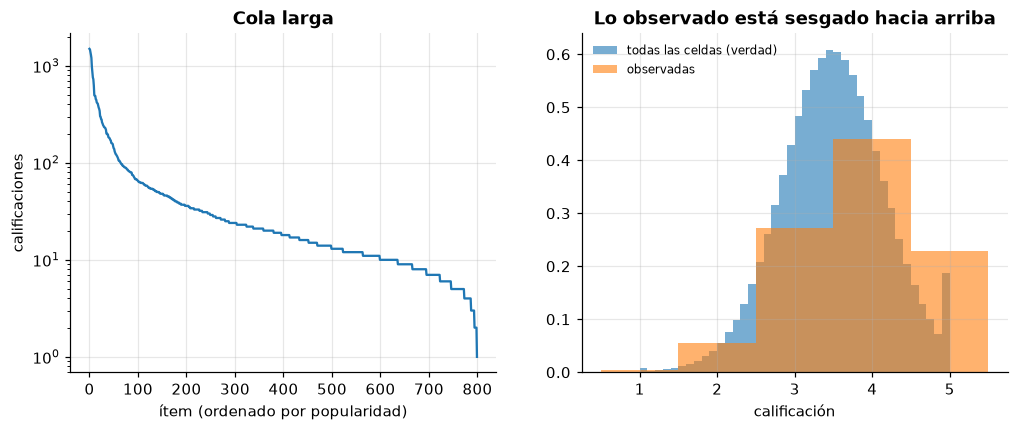

In [2]:
R = to_csr(df, shape)
pop = np.sort(popularity_scores(R))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pop)
axes[0].set(xlabel="ítem (ordenado por popularidad)", ylabel="calificaciones", title="Cola larga")
axes[0].set_yscale("log")
axes[1].hist(
    truth["true"].clip(1, 5).ravel(),
    bins=40,
    density=True,
    alpha=0.6,
    label="todas las celdas (verdad)",
)
axes[1].hist(df["rating"], bins=np.arange(0.5, 6), density=True, alpha=0.6, label="observadas")
axes[1].set(xlabel="calificación", title="Lo observado está sesgado hacia arriba")
axes[1].legend(fontsize=8)
top10 = pop[: len(pop) // 10].sum() / pop.sum()
print(f"el 10 % de ítems más populares concentra el {top10:.0%} de las calificaciones")
real_mean = truth["true"].clip(1, 5).mean()
print(f"media observada {df.rating.mean():.2f} vs. media real de la matriz {real_mean:.2f}")

Con faltantes no aleatorios (MNAR), la media de lo observado sobreestima el gusto promedio:
un modelo entrenado solo con lo observado aprende un mundo más optimista que el real.

## 2. Baselines: media y sesgos

$\hat r_{ui} = \mu + b_u + b_i$. Algunos usuarios califican todo alto; algunos ítems son mejores
que otros. Regularizar encoge los sesgos de ítems con pocas calificaciones.

In [3]:
tr, te = random_split(df, 0.2, seed=0)
Rtr = to_csr(tr, shape)
u, i, y = te.u.to_numpy(), te.i.to_numpy(), te.rating.to_numpy()


def rmse(p):
    return np.sqrt(np.mean((y - p) ** 2))


print(f"media global:          RMSE {rmse(np.full(len(y), tr.rating.mean())):.4f}")
for reg in [0, 5, 25]:
    m = BiasModel(reg_user=reg, reg_item=reg).fit(Rtr)
    print(f"sesgos (λ = {reg:>2}):        RMSE {rmse(m.predict(u, i)):.4f}")

media global:          RMSE 0.8624
sesgos (λ =  0):        RMSE 0.7211
sesgos (λ =  5):        RMSE 0.7147
sesgos (λ = 25):        RMSE 0.7273


## 3. Item-kNN

Predicción = sesgos + promedio ponderado de los residuos del usuario en los ítems más parecidos.
La similitud se calcula sobre residuos (coseno “ajustado”) y se encoge cuando hay pocos usuarios
en común.

In [4]:
bias = BiasModel().fit(Rtr)
for k in [10, 30, 100]:
    for d in [0.0, 0.5]:
        knn = ItemKNN(k=k, shrink=10, denom_reg=d).fit(Rtr, bias)
        print(f"k = {k:>3}, λ_denominador = {d}: RMSE {rmse(knn.predict(u, i)):.4f}")

k =  10, λ_denominador = 0.0: RMSE 0.7925
k =  10, λ_denominador = 0.5: RMSE 0.7054
k =  30, λ_denominador = 0.0: RMSE 0.7861
k =  30, λ_denominador = 0.5: RMSE 0.7023
k = 100, λ_denominador = 0.0: RMSE 0.7349


k = 100, λ_denominador = 0.5: RMSE 0.6996


- **Sin λ en el denominador, kNN es peor que los sesgos** (0.79 frente a 0.715 con k = 10): cada par
  tiene pocos vecinos calificados y el promedio ponderado amplifica el ruido.
- Con λ = 0.5 queda por debajo de los sesgos en todos los k, y mejora con más vecinos (0.700 con k = 100).
- La regularización hace aquí el mismo trabajo que en los sesgos: encoger hacia una predicción
  segura cuando la evidencia es débil.

## Para llevar

- La matriz usuario × ítem está casi vacía y su estructura es de cola larga.
- Los faltantes no son aleatorios: lo observado está sesgado, y eso afecta entrenamiento y evaluación.
- Siempre empezar por los sesgos: son baratos y explican gran parte de la varianza.
- En vecinos, la regularización (en la similitud y en el promedio) separa un modelo útil de uno ruidoso.